# Machine Learning for Computer Vision
Marc HARTLEY - Julien LOMBAERDE

In this project, we are going to give you our contribution to the CROHME (*Competition on Recognition of Online Handwritten Mathematical Expressions*). Since 2011, this competition has the aim to enhance and perfect the state-of-the-art in terms of handwritting recognition.  
In this competition, you are given 3 tasks :
- First: Isolated Symbol Recognition. In this task, you are given mathematical symbols, that you have to recognize.
- Second: Full formulas recognition. Now it's not only a symbol but a whole mathematical expression that you have to recognize.
- Third and last: Matrix recognition. For a reason of time, capacities, studies objectives, we are not going to work on this part.

## Task 1 : Isolated Symbol Recognition
This task is the more complex and challenging of the three tasks, as it is the solid base for the other two.  
The idea here is to look at symbols handwritten and transformed in InkML files, identify the target symbol and retrieve this symbol.
For all this, we are going to use some Convolutional Neural Networks (CNN) in order to process image, extract features and predict the right labels.

### InkML files
InkML files are collected by the use of electronic pen used on tablets. It stores the list of coordinates where the pen got through every $X$ ms. From the moment the pen touches the tablet until it leaves, we call that a stroke. The InkML file stores every strokes in a XML file, where you can also add annotation (about the user, the geolocalisation, etc...)  
In this competition, we are not given of these informations, only the pen coordinates.  

The file convertInkmlToImg.py allows us to transform a stroke to an image by showing a 1px wide stroke.  
Now, let's look at what it looks like.

In [1]:
import matplotlib.pyplot as plt
import convertInkmlToImg
import segmenter
import torch
import torchvision
import re
# Clear memory
import IPython
app = IPython.Application.instance()
#app.kernel.do_shutdown(True)


from PIL import Image
import time
import copy
import os
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
import matplotlib.patheffects as PathEffects
import matplotlib.pyplot as plt
import numpy as np
import itertools
from sklearn.model_selection import KFold
from collections.abc import Iterable
from copy import deepcopy
import random
from pickle import load 
from pickle import dump
import sys
import glob
import pandas as pd
import math
import statistics

plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100


O,hyp0,*,1.0,0
O,hyp1,*,1.0,1
O,hyp2,*,1.0,2
O,hyp3,*,1.0,3
O,hyp4,*,1.0,4
O,hyp5,*,1.0,0,1
O,hyp6,*,1.0,1,2
O,hyp7,*,1.0,2,3
O,hyp8,*,1.0,3,4
O,hyp9,*,1.0,0,1,2
O,hyp10,*,1.0,1,2,3
O,hyp11,*,1.0,2,3,4
O,hyp12,*,1.0,0,1,2,3
O,hyp13,*,1.0,1,2,3,4



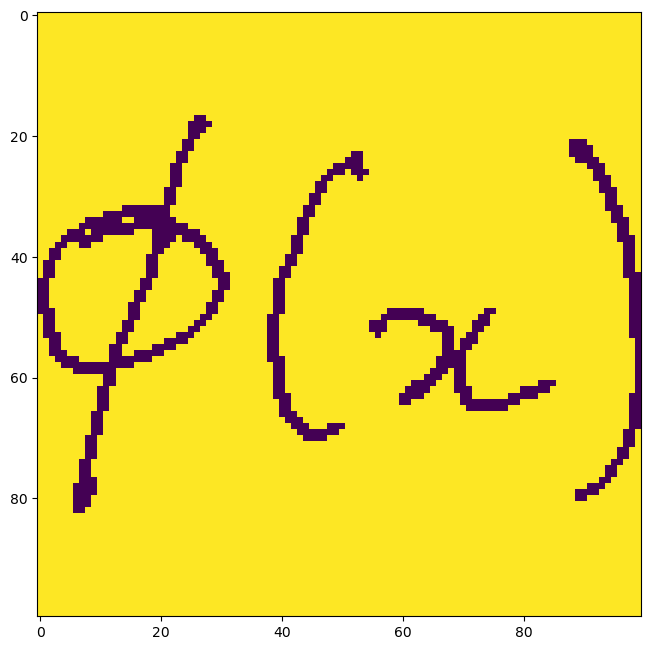

In [2]:
# We select an InkML file we want to work with
#file = "../data/from_server/trainingSymbols/iso79028.inkml" 
file = "../data/formulaire001-equation001.inkml"
# the "inkml" variable contains all the coords for each stroke.
inkml = convertInkmlToImg.parse_inkml(file)
# Number of strokes
nbs = len(inkml)
# The strokes are not always indexed from 0 to N, so we have to save it in a variable
strokes_ids = list(inkml.keys())
# Generate few possible strokes combination, just to see what's the output
hyp = segmenter.generateHypSeg(nbs, strokes_ids)
# We can create a very simple LG file from the previous strokes combinations
txtLG = segmenter.toLG(hyp)
print(txtLG)

# Now, let's see what the input formula looks like :
plt.imshow(convertInkmlToImg.convert_to_imgs(inkml.values(), 100))
plt.show()

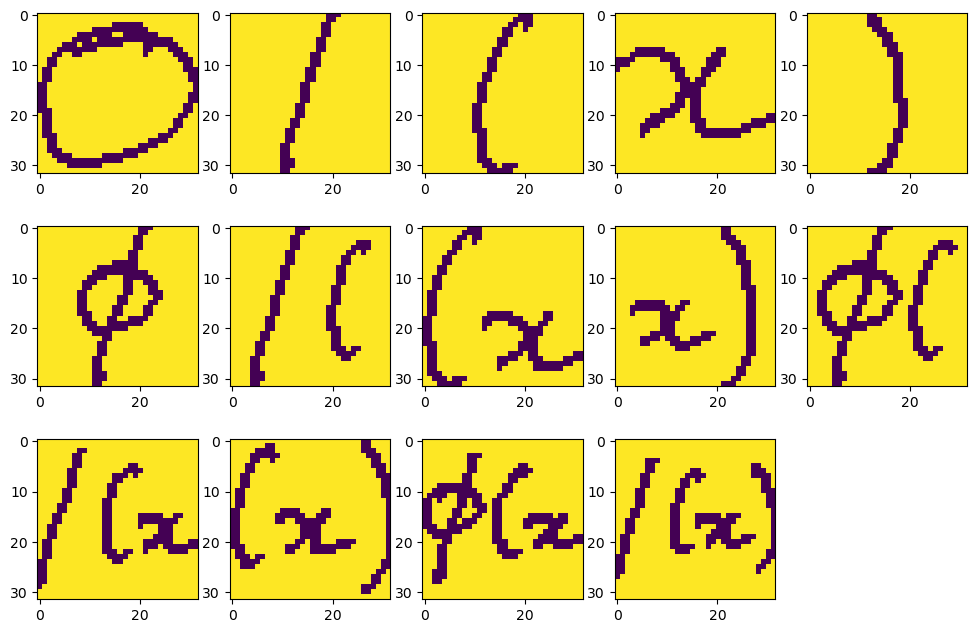

In [3]:
# Display all the combinations previously generated
for i, img in enumerate(convertInkmlToImg.genImgFromLGHypotheses(inkml, txtLG, 32)[:-1], 1):
    plt.subplot(3, 5, i)
    plt.imshow(img)
plt.show()

### Joining strokes together
*This is the latest network structures we were looking at. For more details on our precedent attempts, [please take a look at our Annex here](annexe_1.html).*

As we can see on the previous figure, some combinations are not representing a symbol, but only a part of it (e.g. the $\phi$ sign, that has to be written in a combination of two strokes) or more than a symbol.  
We need to do some cleaning in all this, and that's what our "junk classifier" role will be.  

We are working on images, so the use of a Convolutional Neural Network (CNN) can be relevant. So that means at least a layer of convolution.  
Also, we would like to be robust on strokes property (e.g. the width), so we can use a Max Pooling to avoid this problem.  
Last, we want a binary classifier from the features extracted by the convolutional layers, so we will add some fully connected layers converging into 2 outputs.

So we can expect our network to look like : Conv2d -> MaxPooling -> Conv2d -> Hidden layer -> Output 

We don't really know yet how many convolutions should we need, so we can try to do multiple models and compare them.

In [4]:
class NetCNN(nn.Module):
    def __init__(self, input_size:int, output_size:int, kernel_size:int = 3, number_of_filters:int = 1, number_of_layers:int = 1, hidden_cells:int = 0, dropout = False, lastActivation = None):
        super(NetCNN, self).__init__()
        # If we want a binary output, we use 2 outputs and apply a Softmax function at the end
        is_binary = (output_size == 1) 
        if output_size == 1:
            output_size = 2
            
        # We are using 2^n filters on our convolutions, that choice is simply to try multiple values on a large scale
        number_of_filters = 2**number_of_filters
        # First, a convolution. Here we specified an image with a unique channel (no RGB)
        elems = [nn.Conv2d(1, number_of_filters, kernel_size)]
        input_size -= 2 * int(kernel_size/2)
        
        # For every new "layer" (or block), we add a MaxPooling and a Convolution
        # The number of filters is not changed
        for i in range(1, number_of_layers) :
            elems.append(nn.MaxPool2d(2))
            input_size = input_size // 2
            elems.append(nn.Conv2d(number_of_filters, number_of_filters, kernel_size))
            input_size -= 2 * int(kernel_size/2)
        self.cnn_layers = nn.Sequential(*elems)    
        
        
        input_size = int(input_size**2 * number_of_filters)
        linear = []
        # If an hidden layer is asked, give one
        if hidden_cells > 0 :
            linear.append(nn.Linear(input_size, hidden_cells))
                   
        # Let a dropout on the hidden layer or on the convolutional outputs
        if dropout:
            # The dropout parameter can be a float (0 <= dropout <= 1) 
            # or a boolean, in which case, we give a 50% probability
            dropout_val = dropout if isinstance(dropout, bool) else dropout
            linear.append(nn.Dropout(dropout_val))
                          
        # Close the linear layers
        if hidden_cells > 0 :
            linear.append(nn.Linear(hidden_cells, output_size))
        else:
            linear.append(nn.Linear(input_size, output_size))
                         
        # Apply a final activation function on the output.
        if is_binary:
            linear.append(nn.Softmax(dim=1))
        elif lastActivation:
            linear.append(lastActivation())
        self.linear_layers = nn.Sequential(*linear)
        
    def forward(self, x):
        x = self.cnn_layers(x)
        x = x.view(x.size(0), -1)
        x = self.linear_layers(x)
            
        return x

Nothing really impressive or innovative in this network, but parameterized enough for us to launch a serie of trainings.

We will now define the functions used for the training of the models and the testing :

In [5]:
# Train function, give it your dataset, the parameters of your model, and there you go.
# Arguments:
# - trainloader : the training part of your dataset
# - validationloader : the testing / validation part of your dataset
# - model_class : Specify the class of the model you want to train
# - model_parameters : parameters that will be given to the __init__() function of your model
# - loss_function : Specify the loss function you want to use. default is Cross Entropy
# - training_for_autoencoders : will simply change the target for the loss
# - optimizer : Specify your optimizer. default is SGD
# - learning rate : parameter given to the optimizer
# - num_epochs : number of epochs for the training
# - early stopping : if True, will stop if the validation loss starts increasing
#                   If a integer value, defines the "patience" (number of minibatch to study before officially stops for overfitting)
# - display_precision : if verbose, number of minibatch seen when printing results.
#                 And because we didn't work very well, it also defines the precision for early stopping...
# - verbose : level of verbosity
def train_model(trainloader, 
                validationloader, 
                model_class = NetCNN, 
                model_parameters = {'input_size' : 32, 'output_size' : 101}, 
                loss_function = nn.CrossEntropyLoss, 
                training_for_autoencoder = False, 
                optimizer = None, 
                learning_rate = 0.010, 
                num_epochs = 5, 
                early_stopping = False, 
                display_precision = 100, 
                verbose = True):
    
    minibatchsize = 128
    # If not done, transform datasets in dataLoader
    # We've chose high batch size to be more efficient in time
    if isinstance(trainloader, torch.utils.data.Dataset):
        trainloader = torch.utils.data.DataLoader(trainloader, batch_size=minibatchsize,
                                             shuffle=False, num_workers=0)
    if isinstance(validationloader, torch.utils.data.Dataset):
        validationloader = torch.utils.data.DataLoader(validationloader, batch_size=2 * minibatchsize,
                                             shuffle=False, num_workers=0)
    # Create the CNN from the given parameters :
    net = model_class(**model_parameters)
    net.to(device) # move it to GPU if available

    # Defining loss function and optimizer
    criterion = loss_function()
    if not optimizer:
        optimizer = optim.SGD(net.parameters(), lr=learning_rate, momentum=0.9)

    # Definition of arrays to store the results and draw the learning curves
    val_err_array = np.array([])
    train_err_array = np.array([])
    nb_sample_array = np.array([])

    # best system results
    best_val_loss = math.inf
    best_nb_sample = 0
    best_model =  copy.deepcopy(net)

    nb_used_sample = 0
    running_loss = 0.0
    display_precision = display_precision if display_precision > 1 else len(trainloader)*display_precision -1
    print_every = display_precision

    # Stop if is_overfitting turns to True
    is_overfitting = False
    # number of iteration that are still allowed (depending on "early_stopping")
    left_before_early_stop = False
    
    # Know when you have to display losses
    next_print_in = display_precision

    total_acc = 0
    for epoch in range(num_epochs):  # loop over the dataset multiple times
        if is_overfitting:
            break
            
        start_time = time.time()
        for i, data in enumerate(trainloader, 0):
            if is_overfitting:
                break
            # get the inputs
            inputs, labels = data
            inputs, labels = inputs.to(device), labels.to(device) # if possible, move them to GPU

            # zero the parameter gradients
            optimizer.zero_grad()

            # forward + backward + optimize
            outputs = net(inputs)
            if training_for_autoencoder: # If we train an autoencoder, set the input also as output
                loss = criterion(outputs, inputs)
            else:
                loss = criterion(outputs, labels) # Otherwise, use the label
            loss.backward()
            optimizer.step()
            
            # count how many samples have been used during the training
            nb_used_sample += len(inputs)
            running_loss += loss.item()
            
            next_print_in -= 1
            if next_print_in <= 0:    # print every ""print_every"" mini-batches
                next_print_in = display_precision
                train_err = (running_loss / (print_every * minibatchsize))
                running_loss = 0.0
                #evaluation on validation set
                totalValLoss = 0.0
                # Evaluation part, don't update the weights
                with torch.no_grad():
                    for data in validationloader:
                        images, labels = data
                        images, labels = images.to(device), labels.to(device)
                        outputs = net(images)
                        if training_for_autoencoder: # If we train an autoencoder, set the input also as output
                            loss = criterion(outputs, images)
                        else:
                            loss = criterion(outputs, labels) # Otherwise, use the label
                        totalValLoss += loss.item()
                val_err = (totalValLoss / len(validationloader))
                if verbose > 2:
                    print('\tEpoch %d batch %5d ' % (epoch + 1, i + 1))
                    print('\tTrain loss : %.3f' % train_err)
                    print('\tValidation loss mean : %.3f' % val_err)
                train_err_array = np.append(train_err_array, train_err)
                val_err_array = np.append(val_err_array, val_err)
                nb_sample_array = np.append(nb_sample_array, nb_used_sample)

                # save the model only when loss is better
                if val_err < best_val_loss:
                    best_val_loss = val_err
                    best_nb_sample = nb_used_sample
                    best_model =  copy.deepcopy(net)
                    if early_stopping: # If we want early stopping, we extend the patience
                        left_before_early_stop = int(early_stopping) # Gives 1 if early_stopping === True
                    else:
                        left_before_early_stop = math.inf # Just to be sure that we don't stop the learning
                        
                else: # If the validation loss is lower than before...
                    if early_stopping:
                        left_before_early_stop -= 1
                        if left_before_early_stop < 0:  # Stop the learning to avoid overfitting
                            is_overfitting = True
                            if verbose > 2:
                                print("Stopped due to overfitting!", (nb_used_sample - best_nb_sample)//minibatchsize, "minibatchs before, we were", val_err-best_val_loss, "loss lower")
                            break
        if verbose > 1:
            print("\tEpoch {} of {} took {:.3f}s".format(epoch + 1, num_epochs, time.time() - start_time))
    return {
        'model' : best_model, 
        'train_err' : train_err_array, 
        'val_err' : val_err_array, 
        'nb_samples' : nb_sample_array, 
        'best_val_loss' : best_val_loss, 
        'best_nb_samples' : best_nb_sample} # Return statistics about the training

In [6]:
# Testing the model : we need the model and a dataset
def test_model(model, testloader):
    if not isinstance(testloader, torch.utils.data.DataLoader):
        testloader = torch.utils.data.DataLoader(testloader, batch_size=128,
                                             shuffle=False, num_workers=0)
    else:
        testloader = testingset
        
    # number of classes depends on the model
    nb_classes = len(list(model.parameters())[-1])
    # Store a confusion matrix
    confusion = np.zeros((nb_classes, nb_classes), int)
    results = {}
    # Check the results for each class
    class_correct = list(0. for i in range(nb_classes))
    class_total = list(0. for i in range(nb_classes))
    with torch.no_grad():
        for data in testloader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1) # Get the most probable prediction
            c = (predicted == labels).squeeze()  # Check with ground truth
            try:
                len(c) # If "c" is an array, it's good
            except:
                c = c.unsqueeze(0) # otherwise we need to add a dimension
                
            for i in range(len(labels)): # Update the confusion matrix
                label = labels[i]
                class_correct[label] += c[i].item()
                class_total[label] += 1
                confusion[label, predicted[i]] += 1

    # compute results
    correct = 0
    total = 0
    for i in range(nb_classes):
        if class_total[i] > 0 :
            correct += class_correct[i]
            total += class_total[i]
            results[i] = {
                'acc' : class_correct[i] / class_total[i], 
                'correct_samples' : class_correct[i], 
                'total_samples' : class_total[i]} # Store the accuracy and the sample size for each class
        else:
            results[i] = {'acc' : 0, 'correct_samples' : 0, 'total_samples' : 0}
            
    # Store the global accuracy and the confusion matrix and return everything
    results['global'] = {'acc' : correct / total, 'correct_samples' : correct, 'total_samples' : total}
    results['confusion'] = confusion
    return results

Before going further, we want to automatize the training of multiple models. So we defined functions for this.  

In [7]:
# From a set of parameters, create all the combinations possible
def create_all_combinaisons(hyperparameters):
    combinaisons = [hyperparameters]
    for param in hyperparameters: # For each parameter
        if isinstance(hyperparameters[param], Iterable) : # Check if it's iterable (if not, it's a fix value)
            i = 0
            while i < len(combinaisons):                          # Iterate on each stored combination
                if isinstance(combinaisons[i][param], Iterable):  # Check if this parameter is unfix
                    combinaisons.append(deepcopy(combinaisons[i])) 
                    combinaisons[i][param] = combinaisons[-1][param].pop(0) # In this case, duplicate the parameter 
                    if len(combinaisons[-1][param]) == 1:
                        combinaisons[-1][param] = combinaisons[-1][param][0] # and add a fix value
                i += 1
    return combinaisons

# Launch the training function for every possible combination. 
# Arguments:
# - hyperparameters : all the parameters that can be changed in the model
# - trainset : the training set
# - validset : validation set
# - testingset : test set
# - model_class : Specify the class of the models you want to train
# - loss_function : Specify the loss function you want to use. default is Cross Entropy
# - training_for_autoencoders : will simply change the target for the loss
# - optimizer : Specify your optimizer. default is SGD
# - learning rate : parameter given to the optimizer
# - num_epochs : number of epochs for the training
# - early stopping : if True, will stop if the validation loss starts increasing
#                   If a integer value, defines the "patience" (number of minibatch to study before officially stops for overfitting)
# - save_as : specify the name of the file where we save all the statistics (including the model itself)
#                   a timestamp is added to the file name
# - start_from_begining : remove all previously saved models if True, otherwise will ignore previously calculated combinations
# - verbose : level of verbosity

def try_all_models(hyperparameters, 
                   trainset, 
                   validset,
                   testingset, 
                   model_class = NetCNN, 
                   loss_function = nn.CrossEntropyLoss, 
                   optimizer = False,
                   training_for_autoencoder = False, 
                   learning_rate = 0.001, 
                   num_epochs = 5, 
                   display_precision = 1.0,
                   early_stopping = True, 
                   save_as = False, 
                   start_from_begining = True, 
                   verbose = 3,
                   max_number_of_models = math.inf):
    models = []
    combinaisons = create_all_combinaisons(hyperparameters) # Get all possible combinations
    combinaisons_done = []
    if start_from_begining: # Remove previously saved models if "start_from_begining" is True
        for file in glob.glob(os.path.splitext(save_as)[0] + "*" + os.path.splitext(save_as)[1]):
            os.remove(file)
    else:
        if not save_as:
            if verbose > 0:
                print("No filename has been given as the 'save_as' argument. We cannot retreive pretrained models")
        else:
            # Look for all pretrained models
            for file in glob.glob(os.path.splitext(save_as)[0] + "*" + os.path.splitext(save_as)[1]):
                models = load(open(file, "rb"))
                for model in models:
                    combinaisons_done.append(model['parameters'])
                models = [] # save a little bit of memory
            
            if verbose > 1:
                print(len(combinaisons_done), "models have been retrieved and ignored")
                
    if len(combinaisons_done) >= min(max_number_of_models, len(combinaisons)): # If there is nothing to train
        if verbose > 0:
            print("No new model to train")
        return models
    
    random.shuffle(combinaisons) # Shuffle to train in a random order, 
            # so that you can stop early and still have interesting data
    current_combination_number = 0
    for i, parameters in enumerate(combinaisons, 1):
        if len(combinaisons_done) + current_combination_number >= max_number_of_models:
            return models
        current_combination_number += 1
        models = []
        start_time = time.time()
        if verbose > 0:
            print(F"Trying combinaison {current_combination_number} / {len(combinaisons) - len(combinaisons_done)} ...")
        if verbose > 1:
            for param in parameters:
                print("    %15s"% param, " : ", parameters[param])
        if parameters in combinaisons_done:
            current_combination_number -= 1
            if verbose > 0:
                print("Ignored (pretrained)")
            continue
            
            
        # Save the training statistics (with the model itself), the testing statistics and the parameters used
        current_model = {}
        current_model['training'] = train_model(trainloader = copy.deepcopy(trainset), 
                                                validationloader = copy.deepcopy(validset), 
                                                model_class = model_class, 
                                                model_parameters = parameters, 
                                                loss_function = loss_function, 
                                                training_for_autoencoder = training_for_autoencoder, 
                                                optimizer = optimizer,
                                                learning_rate = learning_rate, 
                                                num_epochs = num_epochs, 
                                                early_stopping = early_stopping, 
                                                display_precision = display_precision, 
                                                verbose = verbose -1)
        current_model['test'] = test_model(current_model['training']['model'], copy.deepcopy(testingset))
        current_model['parameters'] = parameters
        models.append(current_model)
        
        if verbose > 1:
            print("Found an accuracy of ", current_model['test']['global']['acc'], "(", current_model['test']['global']['total_samples'], " used) from the ", current_model['training']['best_nb_samples'], "samples")
        
        # Save file at every iteration to by able to stop anytime
        if save_as:
            if len(models) > 0:
                file = os.path.split(os.path.splitext(save_as)[0])[-1]
                ext = os.path.splitext(save_as)[1]
                directory = os.path.join(*os.path.split(os.path.splitext(save_as)[0])[:-1])
                if not os.path.exists(directory):
                    os.makedirs(directory)
                dump(models, open(os.path.join(directory, file + "_" + str(time.time()) + ext), "wb+"))
            else:
                print("No model to save")
        if verbose > 1:
            print("Trained in", round(time.time() - start_time), "seconds")
    return models

Some of you will notice that we are not using cross-validation. Yes. And why's that? Simply because in a first time we didn't want to be time consuming... That will be changed in a future version, but not now, sorry.

We had to modify the dataset so that the images coming from the CROHME dataset are labelled "real" and from the Junk dataset they are labelled "junk". As the two datasets have completely different sizes, we increase the number of "junks" by simply duplicating the samples. An intelligent way to do that would be to apply transformations on the junk, so that it could be more robust, but for time purposes, we didn't.

In [8]:
# Scan a directory and retrieve all filenames matching the RegEx
def get_all_files(directory = ".", regexp="^.*\.png$", recursive = False, shuffle = True):
    patt_re = re.compile(regexp)
    data = None
    if recursive:
        dirlist = [os.path.relpath(os.path.join(dp, f)) for dp, dn, fn in os.walk(os.path.expanduser(directory)) for f in fn if patt_re.match(f)]
    else:
        dirlist = [f for f in os.listdir(directory) if patt_re.match(f)]
    if shuffle :
        random.shuffle(dirlist)
    return dirlist


# For this dataset, you can provide the root directory for the "symbols" and the root of the "junk" and 
# it will label the symbols as 0 and the junk at 1
# Note that we do not randomize our "x" and targets, so be sure to apply a random_split or something like this :)
class JunkNotJunkDataset(torch.utils.data.Dataset):
    def __init__(self, CROHME_dir, junk_dir, transform=None, balance=False):
        # get files for each category
        self.junk = get_all_files(junk_dir, recursive = True)
        self.CROHME = get_all_files(CROHME_dir, recursive = True)
        
        if balance: # If we want a balanced dataset, we reduce the number of samples to get a 50-50
            # But here it's not the case because we want to prioritize the CROHME and keep a low number of junk
            max_size = max(len(self.CROHME), len(self.junk))
            self.CROHME = self.CROHME * int(max_size / len(self.CROHME))
            self.junk = self.junk * int(max_size / len(self.junk))
        # concatenate all files and targets
        self.x = np.concatenate((self.CROHME, self.junk), axis = 0)
        self.y = torch.Tensor([0] * len(self.CROHME) + [1] * len(self.junk))
        self.targets = self.y
        
        self.classes = ['real', 'junk']
        self.transform = transform

    def __getitem__(self, index):
        # Get the file, load the image, apply transformation
        img = Image.open(self.x[index])
        #img = img.resize((32, 32))
        if self.transform is not None:
            img = self.transform(img)
        
        label = self.y[index]
        return (img, label.long())

    def __len__(self):
        return len(self.y)

#device = torch.device("cpu")
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu") # If possible, move to CUDA

# Transformations on the dataset
# Some data augmentation should be done, maybe later
transform = transforms.Compose(
    [transforms.Pad(2),
     #transforms.Grayscale(), # Images are already on 1 channel
     transforms.Resize(32),
     transforms.ToTensor()])

# Create the dataset, divide it in a training and testing set. 
dataset = JunkNotJunkDataset("../../../data/CROHME", "../../../data/CROHME_junk_png", transform=transform, balance = True)
ratio_train_set = 70/100
ratio_valid_set = 15/100

train_size = int(ratio_train_set * len(dataset))
valid_size = int(ratio_valid_set * len(dataset))
test_size = len(dataset) - (train_size - valid_size)
trainset_crohme, validset_crohme, testset_crohme = torch.utils.data.random_split(dataset, [train_size, valid_size, test_size])

In [9]:
path_to_save_cnn = "trained_models/" + device.type + "/junk_not_junk_model.model"
path_to_save_recognition_cnn = "trained_models/" + device.type + "/recognition_model.model"

# Parameters to vary on the models
models_hyperparameters = {
    'input_size' : 32,
    'output_size' : 1,
    'kernel_size' : [3, 5], 
    'number_of_filters' : [2, 3, 4, 5], 
    'number_of_layers' : [1, 2, 3], 
    'hidden_cells' : [0, 100, 150], 
    'dropout' : [True, False]
}


try_all_models(models_hyperparameters, 
               trainset_crohme, 
               validset_crohme,
               testset_crohme, 
               loss_function = nn.CrossEntropyLoss, 
               verbose = 10, 
               learning_rate = 0.001,
               training_for_autoencoder = False,
               save_as = path_to_save_cnn, 
               start_from_begining = False, 
               display_precision = 0.5,
               early_stopping = 10, 
               num_epochs = 10,
               max_number_of_models = 30)

34 models have been retrieved and ignored
No new model to train


[]

Great, now we have loooots of models. We want to keep the best one, so let's see how it went for the training:

In [10]:
def display_models(filename, ignore_if_accuracy_lower = 0.0, ignore_if_val_err_higher = math.inf, max_y_val = 0.20):
    models_results = []
    validation_results = []
    for file in glob.glob(os.path.splitext(filename)[0] + "*" + os.path.splitext(filename)[1]):
        models = load(open(file, "rb"))
        for model in models:
            plt.plot(np.array(model['training']['nb_samples'])/1000, model['training']['val_err'])
            if model['training']['val_err'][-1] <= max_y_val:
                plt.text(model['training']['nb_samples'][-1]/1000, model['training']['val_err'][-1], str(round(model['test']['global']['acc']*100, 2)) + "%", horizontalalignment="left", fontsize = "x-small", path_effects=[PathEffects.withStroke(linewidth=3, foreground="w")])
            _models_results = {**model['parameters'], 'number_of_samples' : f"{model['training']['best_nb_samples']:,}", 'test_results' : model['test']['global']['acc']}
            models_results.append(deepcopy(_models_results))
            for attr in _models_results:
                if hasattr(_models_results[attr], 'dec') and hasattr(_models_results[attr], 'enc'):
                    models_results[-1]['number_of_layers'] = len(_models_results[attr].enc) // 3
                    models_results[-1]['kernel_size'] = str(list(_models_results[attr].enc[0].parameters())[0][0].size(1))
                    models_results[-1] = dict(models_results[-1])
                    del models_results[-1][attr]
            

    df = pd.DataFrame(models_results)
    #plt.ylim((0, min(max_y_val, plt.ylim()[1])))
    plt.xlabel("Number of samples (x1000)")
    plt.ylabel("Validation loss")
    return df

,input_size,output_size,kernel_size,number_of_filters,number_of_layers,hidden_cells,dropout,number_of_samples,test_results
10,32,1,5,5,3,0,False,"1,149,625",0.796132
13,32,1,5,3,3,150,False,"1,152,057",0.794423
31,32,1,3,5,3,0,False,"1,149,625",0.784393
2,32,1,5,5,2,150,False,"1,149,625",0.780926
8,32,1,5,5,2,0,False,"1,210,169",0.771738
14,32,1,5,4,1,0,False,"1,152,057",0.767429
11,32,1,5,4,1,150,False,"1,091,385",0.765101
17,32,1,3,4,1,150,False,"970,120",0.764878
6,32,1,3,5,1,100,False,"786,598",0.764779
15,32,1,5,2,2,100,False,"1,091,385",0.764704


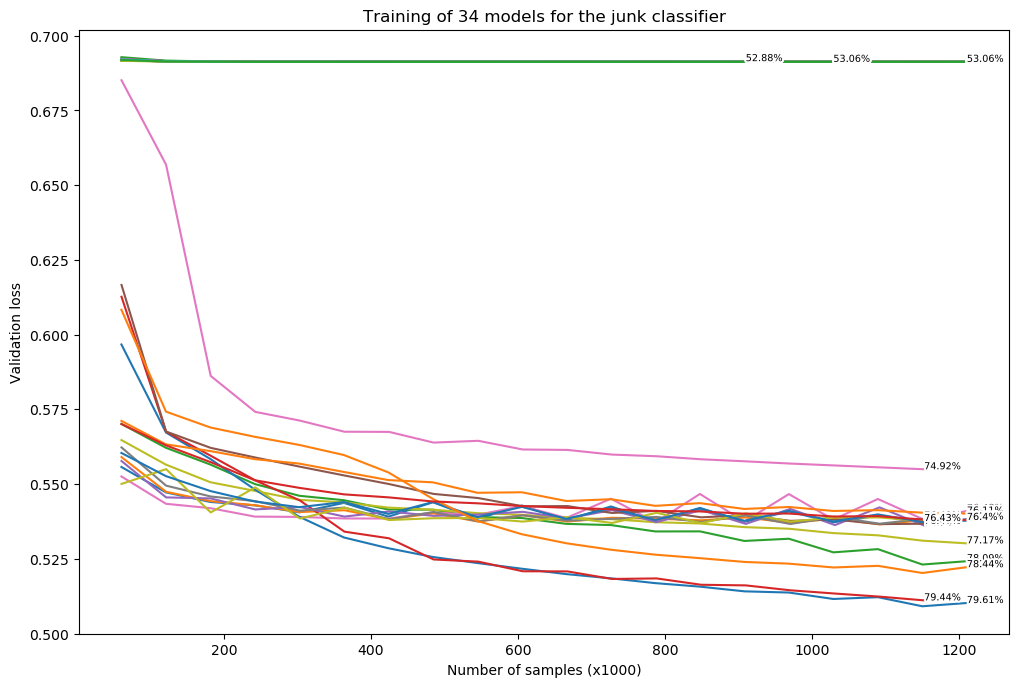

In [11]:
df_junk = display_models(path_to_save_cnn, max_y_val = math.inf).sort_values(by="test_results", ascending = False)
plt.title("Training of %d models for the junk classifier" % len(df_junk))
df_junk

We can see 2 groups of networks : 
- Those who didn't learn and sticked to an accuracy of ~50%
- Those who learned, with an accuracy of 75% to 80%

It looks like it's the "Dropout" variable that creates this difference, but we didn't have time to check the reason of this difference.  If we take a closer look on the best models, we see that a higher number of layers can lead to better results. Also a high number of filters seems to increase the accuracy (Note that the real number of filters is defined by $2 ^{nb\_filters}$ ) . It could have been interesting to try deeper models, but for memory reasons, we did not.  
Also, we did not apply padding in our covolutions, which limit us in the depth of our network.

Looking at the learning curves, it looks like the training for some models (especially those who have 3 convolutionnal layers) could be trained longer before overfitting, but for some timing reasons, we didn't continue. 

Okay, now let's select the best one by comparing their accuracies.  
If we used cross-validation, we should also take into account the variance in the results on each fold. So this simple training is very simplifying here.  

In [12]:
def group_files_and_keep_best(filename, verbose=False):
    models_results = []
    files_saw = []
    all_files = glob.glob(os.path.splitext(filename)[0] + "*" + os.path.splitext(filename)[1])
    best_accuracy = 0.0
    kept_model = None
    for i, file in enumerate(all_files, 1):
        if verbose:
            print("File", i, "/", len(all_files), "...")
        files_saw.append(file)
        models = load(open(file, "rb"))
        for model in models:
            if model['test']['global']['acc'] > best_accuracy:
                best_accuracy = model['test']['global']['acc']
                kept_model = model
        models_results += models
        os.remove(file)
        
    file = os.path.split(os.path.splitext(filename)[0])[-1]
    ext = os.path.splitext(filename)[1]
    directory = os.path.join(*os.path.split(os.path.splitext(filename)[0])[:-1])
    
    save_all_at = os.path.splitext(filename)[0] + "_" + str(int(time.time())) + ext
    save_best_at = os.path.join(directory, "best_" + file + ext)
    dump(models_results, open(save_all_at, "wb+"))
    dump(kept_model, open(save_best_at, "wb+"))
    return kept_model

best_junk_model = group_files_and_keep_best(path_to_save_cnn)
best_junk_model['training']['model']

NetCNN(
  (cnn_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1))
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1))
  )
  (linear_layers): Sequential(
    (0): Linear(in_features=32, out_features=2, bias=True)
    (1): Softmax(dim=1)
  )
)

Accuracy of   real : 86 % (18564/21425) -> OK
Accuracy of   junk : 71 % (13583/18954) -> OK
-> Global accuracy : 79 % (32147/40379)


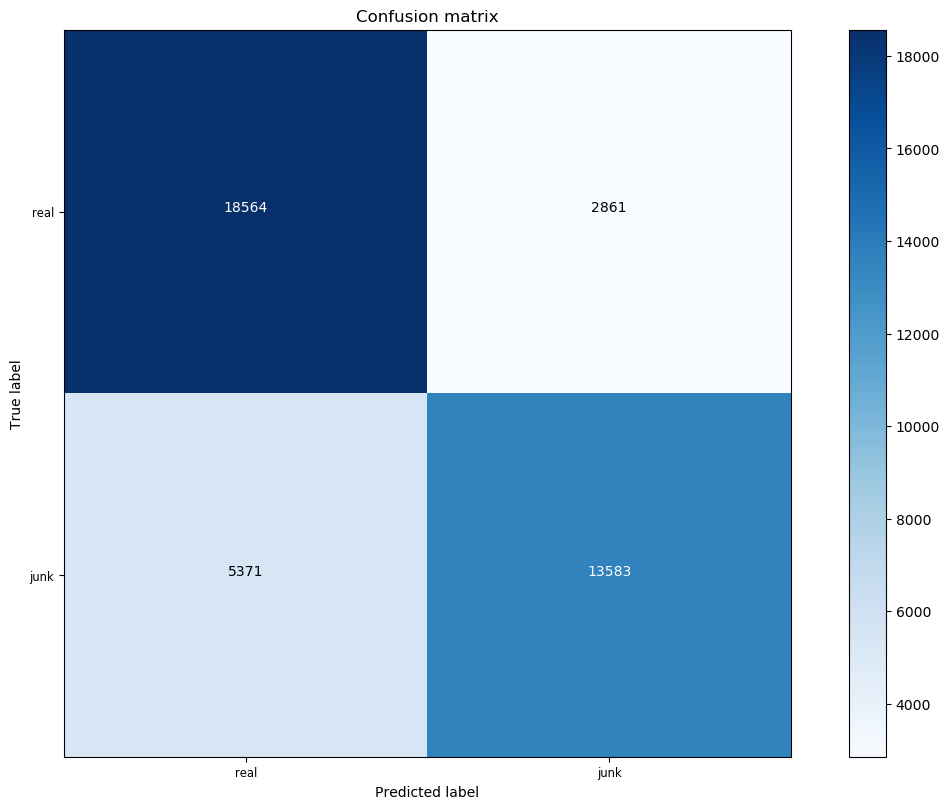

In [13]:
# Code taken from https://deeplizard.com/learn/video/0LhiS6yu2qQ
def plot_confusion_matrix(cm, classes):
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion matrix')
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    x_rotation = 0 
    tick_size = "small"
    if len(classes) < 20:
        pass
    elif len(classes) < 50:
        x_rotation = 45
        tick_size = "x-small"
    else:
        x_rotation = 45
        tick_size = "xx-small"
        
    plt.xticks(tick_marks, classes, rotation = x_rotation, fontsize=tick_size)
    plt.yticks(tick_marks, classes, fontsize=tick_size)

    thresh = cm.max() / 2.
    if len(classes) < 20:
        for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
            plt.text(j, i, cm[i, j], horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    
def display_test_results(results, classes):
    for classe in results:
        if classe == 'confusion' : 
            continue
        if classe == 'global' :
            print("-> Global accuracy : %2d %% (%3d/%3d)" % (100 * results[classe]['acc'], results[classe]['correct_samples'] , results[classe]['total_samples']))
            continue
        most_seen = classes[list(results['confusion'][classe]).index(max(results['confusion'][classe]))]
        if most_seen == classes[classe]:
            print('Accuracy of %6s : %2d %% (%3d/%3d) -> OK' % (
                classes[classe], 100 * results[classe]['acc'], results[classe]['correct_samples'] , results[classe]['total_samples']))
        else:
            print('Accuracy of %6s : %2d %% (%3d/%3d) -> mostly seen as "%6s"' % (
                classes[classe], 100 * results[classe]['acc'], results[classe]['correct_samples'] , results[classe]['total_samples'], most_seen))
    plot_confusion_matrix(results['confusion'], classes)
    
display_test_results(best_junk_model['test'], dataset.classes)
best_junk_not_junk_cnn = best_junk_model['training']['model']

As we can see, our best model for the "junk/not junk" classifier has a structure of 3 convolution layers (convolution with 32 5x5kernels + a 2x2 max pooling).

And we find an accuracy of 79%. We were hoping for better results for a binary classifier, but we have to stick with that for now.  
With a little bit more work, we could have designed a more complex algorithm for this classifier, like a classifier for one-stroke symbols (e.g. "$\sum$"), one for symbols on which the strokes are overlapping (e.g "$x$", where the two strokes crosses) and an other one for multi-strokes symbols non-overlapping (e.g. "$\lim$"). In a future version, this could be taken into account.

Anyway, now, theorically, we can see if the symbols of the InkML file are real symbols or not.

### Recognizing the symbols
We now want to recognize the symbols that the first classifier considered as real symbols.  
For this, big surprise : a CNN!  

To get a more robust network, we increased the number of samples and applied randomly transformations on the images :
- Small rotations (less than 10°)
- Gaussian blur
- Perspective

We did not balance the dataset to increase the samples of poor-representated classes, this could be done in a future version.

And we know what to do now, let's do that quickly :

In [14]:
# Source : https://prodevsblog.com/questions/132234/set-partitions-in-python/

def slice_by_lengths(lengths, the_list):
    for length in lengths:
        new = []
        for i in range(length):
            new.append(the_list.pop(0))
        yield new

def partition(number):
    return {(x,) + y for x in range(1, number) for y in partition(number-x)} | {(number,)}

def subgrups(my_list):
    partitions = partition(len(my_list))
    permed = []
    for each_partition in partitions:
        permed.append(set(itertools.permutations(each_partition, len(each_partition))))

    for each_tuple in itertools.chain(*permed):
        yield list(slice_by_lengths(each_tuple, deepcopy(my_list)))
        
def return_partition(my_list,num_groups):
    filtered=[]
    for perm in itertools.permutations(my_list,len(my_list)):
        for sub_group_perm in subgrups(list(perm)):
            if len(sub_group_perm)==num_groups:
                #sort  within each partition
                sort1=[sorted(i) for i in sub_group_perm]
                #sort by first element of each partition
                sort2=sorted(sort1, key=lambda t:t[0])
                if sort2 not in filtered:
                    filtered.append(sort2)
    return filtered

In [15]:
transform_recognition = transforms.Compose(
    [transforms.Pad(2),
     transforms.Grayscale(),
     transforms.Resize(32),
     transforms.ToTensor()])

models_hyperparameters_for_recognition = {
    'input_size' : 32,
    'output_size' : 101,
    'kernel_size' : [3, 5], 
    'number_of_filters' : [4, 5, 6], 
    'number_of_layers' : [1, 2, 3], 
    'hidden_cells' : [0, 150], 
    'dropout' : False
}

def create_combinations_of_transformations(transformations):
    subs = list(subgrups(transformations))
    all_transformations = []
    for s in subs:
        for ss in s:
            if not ss in all_transformations:
                all_transformations.append(ss)
    return all_transformations

class AugmentedDataset(torch.utils.data.Dataset):
    def __init__(self, root, transform=None, additional_transforms=[], data_augmentation = 2.0):
        #super(AugmentedDataset, self).__init__(root = CROHME_dir, transform=transform)
        # get files for each category
        self.x = get_all_files(root, recursive = True)
        
        self.classes = list(np.unique(list(map(lambda file: os.path.split(os.path.dirname(file))[-1], self.x))))
        self.targets = list(map(lambda file: self.classes.index(os.path.split(os.path.dirname(file))[-1]), self.x))
        self.y = self.targets
        
        self.transform = transform
        self.additional_transforms = additional_transforms
        
        self.data_augmentation = data_augmentation
        
        self.combination_transform = create_combinations_of_transformations(additional_transforms) + [[]]

    def __getitem__(self, index):
        real_index = int(index / self.data_augmentation)
        # Get the file, load the image, apply transformation
        img = Image.open(self.x[real_index])
        if self.transform is not None:
            img = self.transform(img)
            
        applied_transforms = random.choice(self.combination_transform)
        for transform in applied_transforms:
            img = transform(img)
        
        label = self.y[real_index]
        return (img, label)

    def __len__(self):
        return int(len(self.y) * self.data_augmentation)
    
CROHME_dataset = AugmentedDataset(root = '../../../data/CROHME', 
                                  transform = transform_recognition, 
                                  additional_transforms = [
                                      transforms.RandomPerspective(p=1.0),
                                      transforms.RandomRotation(10),
                                      transforms.GaussianBlur(3)
                                    ],
                                  data_augmentation = 4
                                 )

ratio_train_set = 70/100
ratio_valid_set = 15/100

train_size = int(ratio_train_set * len(CROHME_dataset))
valid_size = int(ratio_valid_set * len(CROHME_dataset))
test_size = len(CROHME_dataset) - (train_size - valid_size)
trainset_recognition, validset_recognition, testset_recognition = torch.utils.data.random_split(CROHME_dataset, [train_size, valid_size, test_size])

try_all_models(models_hyperparameters_for_recognition, 
               trainset_recognition, 
               validset_recognition,
               testset_recognition, 
               loss_function = nn.CrossEntropyLoss, 
               verbose = 10, 
               learning_rate = 0.005,
               training_for_autoencoder = False,
               save_as = path_to_save_recognition_cnn,
               display_precision = 0.5,
               start_from_begining = False, 
               early_stopping = 10, 
               num_epochs = 10,
               max_number_of_models = 10)

11 models have been retrieved and ignored
No new model to train


[]

,input_size,output_size,kernel_size,number_of_filters,number_of_layers,hidden_cells,dropout,number_of_samples,test_results
0,32,101,3,6,3,0,False,"2,572,782",0.859024
10,32,101,3,6,3,150,False,"2,572,782",0.850411
3,32,101,5,5,3,0,False,"2,572,782",0.846297
4,32,101,5,6,2,0,False,"2,572,782",0.812067
8,32,101,3,6,2,150,False,"2,444,142",0.802021
6,32,101,5,4,2,150,False,"2,315,504",0.800739
1,32,101,3,5,2,0,False,"2,572,782",0.797277
7,32,101,3,5,2,150,False,"2,444,142",0.792802
5,32,101,3,4,2,0,False,"2,572,782",0.789958
2,32,101,5,6,1,150,False,"2,572,782",0.537715


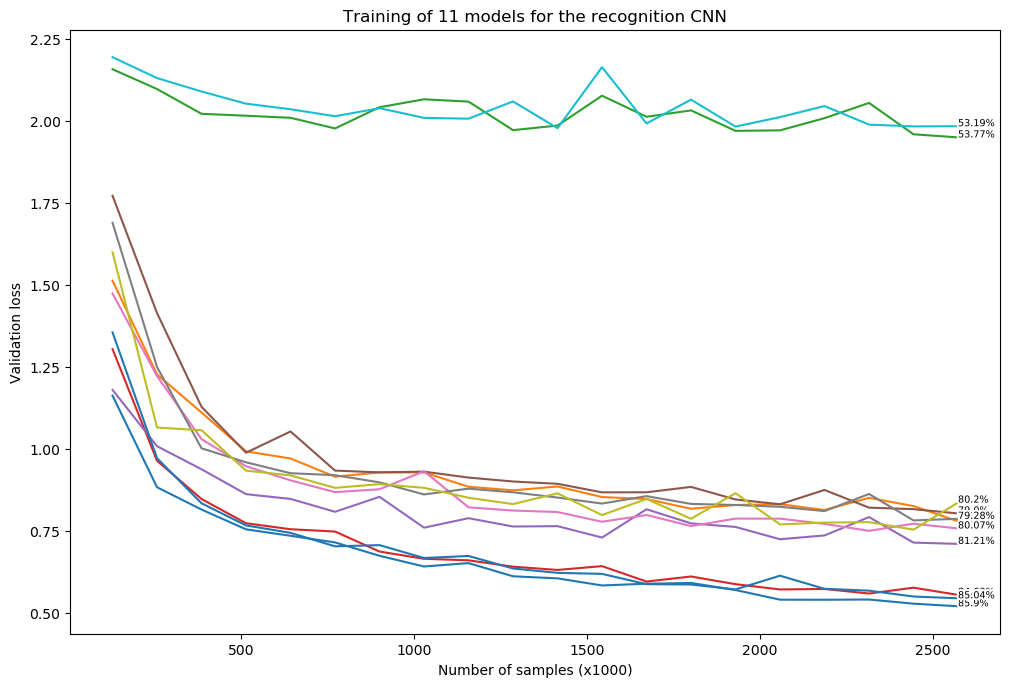

In [27]:
df_recognition = display_models(path_to_save_recognition_cnn, max_y_val = math.inf).sort_values(by="test_results", ascending = False)
plt.title("Training of %d models for the recognition CNN" % len(df_recognition))
df_recognition

Once again, we can see that deep neural networks could be efficient. The number of filters (once again, we have to read this number as $real\ number\ of\ filters = 2^{nb\_filters}$) on the convolutions is influencing the accuracy, unlike the adding of an hidden layer on the linear part of the models.

By keeping the classifier with the best accuracy, that is what we get :

In [17]:
best_recognition_model = group_files_and_keep_best(path_to_save_recognition_cnn)

Accuracy of      ! : 90 % ( 93/103) -> OK
Accuracy of      ( : 95 % (3805/3965) -> OK
Accuracy of      ) : 95 % (3843/4027) -> OK
Accuracy of      + : 95 % (5120/5374) -> OK
Accuracy of      , : 24 % (152/620) -> mostly seen as "div_op"
Accuracy of      - : 98 % (7905/7986) -> OK
Accuracy of      0 : 88 % (1568/1771) -> OK
Accuracy of      1 : 90 % (5691/6294) -> OK
Accuracy of      2 : 88 % (5428/6105) -> OK
Accuracy of      3 : 94 % (2362/2509) -> OK
Accuracy of      4 : 88 % (1461/1653) -> OK
Accuracy of      5 : 80 % (774/961) -> OK
Accuracy of      6 : 86 % (638/739) -> OK
Accuracy of      7 : 88 % (689/782) -> OK
Accuracy of      8 : 88 % (649/734) -> OK
Accuracy of      9 : 81 % (625/766) -> OK
Accuracy of      = : 97 % (3399/3487) -> OK
Accuracy of     A_ : 88 % (217/244) -> OK
Accuracy of     B_ : 77 % (181/233) -> OK
Accuracy of     C_ :  6 % ( 15/226) -> mostly seen as "     c"
Accuracy of  Delta : 81 % ( 30/ 37) -> OK
Accuracy of     E_ : 84 % (129/153) -> OK
Accuracy of   

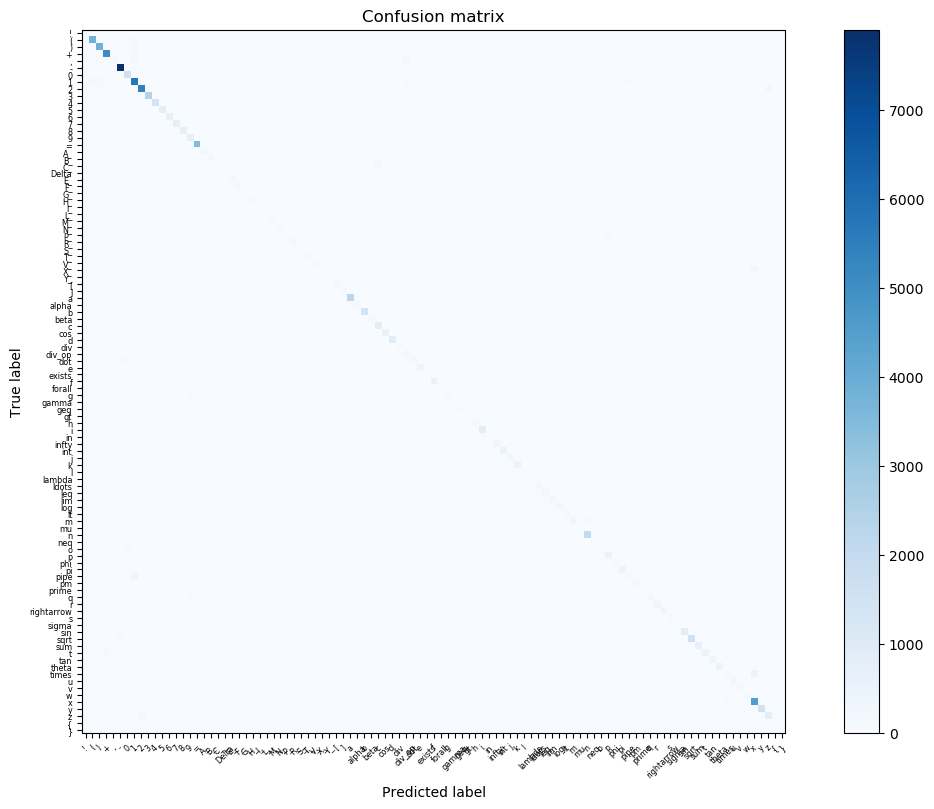

In [18]:
display_test_results(best_recognition_model['test'], CROHME_dataset.classes)

Most of the classes are recognized, and even if some are mislabelled, it's almost always in a logical way :
- capital letters seen as lowercase letters,
- "$\forall$" seen as "$y$",
- "$l$", "$|$", "$\prime$" seen as "$1$"
- "$\times$" seen as "$x$"
- "$o$" seen as "$0$"

Some of these errors could have been easily done by a human

In [19]:
best_recognition_model['training']['model']

NetCNN(
  (cnn_layers): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  )
  (linear_layers): Sequential(
    (0): Linear(in_features=1024, out_features=101, bias=True)
  )
)

Great, we now have found a classifier that can recognize the symbol in 85% of the cases, not bad! The structure is almost the same as the one found for the binary classifier : 3 convolutional layers (convolution of 64 3x3kernels + a 2x2 max pooling) without any hidden layer.  

So in this part, we trained a classifier to check if an image is a mathematical symbol or not, and if it's the case, a second classifier is able to recognize this specific symbol. The theorical accuracy of our two models on a symbol is $acc_{junk\ classifier} * acc_{symbol\ classifier}$. The task 1 is finished. 

For a more precise and stable model, we should have taken into account the unbalance of the classes of the dataset, but this will be the improvement for a future version.

We still need to use them on the second task, so let's move on.

## Task 2 : Layout Analysis
In the next task, the goal is to understand the layout between all of the symbols of an expression. Reading $x+1$ is quite easy, we just have to recognize $x$, then $+$ and $1$ and put them one next to the other. But what about $x^41$? Here we have to understand that $41$ is a "superscript" for $x$. Same for $H_2 O$ with subscripts.  

In fact there are *Above* and *Below* ($\frac{A}{B}$), *Superscript* ($x^2$), *Subscript* ($A_{ij}$), *Inside* ($\sqrt{x}$) and *Right* ($x+1$).

We decided to use a simple way to distinguish all of them, by using bounding boxes.  
- Subscripts and superscripts "center" must be lower/higher than the related symbol's bounding box, and be on the right. We also precised that the two symbols should not be too far away from each other.
- There's an above of below relation if their Y-position is upper / lower than the related symbol's bounding box
- It's Right-related if the objects are on the right and is not a subscript/superscript
- It's Inside if the center of the object is inside of the bounding box of the other object.

All the relations will be indicated in a Label Graph.

### Label Graphs (LG files)
The output of our algorithms must be an LG (Label Graph) file. These files are organized in two parts :
- First, we declare the different symbols that are used in the expression
- Then we explicit the relation between each of them with *Above*, *Below*, *Superscript*, *Subscript*, *Right*, *Inside*.

Here is an example of an LG file for $2x + x^2 + 1$ :

A line starting by a "O" is declaring a new symbol of the expression. The syntax is $O, [name], [symbol], [probability\ of\ the\ symbol], [stroke\ number(s)]$  .
Each symbol must have a unique name that will be used in the relation part.

The lines starting with "R" are declaring a relation between symbols. The syntax is $R, [symbol_1], [symbol_2], [relation\ type], [probability\ of\ the\ relation]$.  
Here we didn't use a regressor or classifier for the layout analysis so we will just assign 1.0 to the probability

### Our method to define the layout
Let's see the use of our classifiers to select the symbols that should be kept or not, and if so, recognize the symbol :

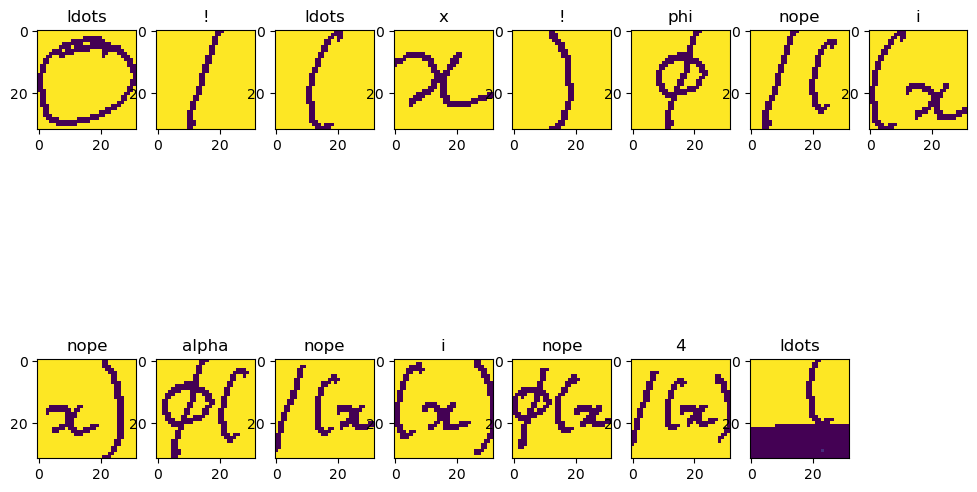

In [20]:
def computeProbSeg(im, junk_classifier, saveIm = False):
    #im = convertInkmlToImg.convert_to_imgs(convertInkmlToImg.get_traces_data(alltraces, hyp[1]), 32)
    if saveIm:
        imsave(hyp[0] + '.png', im)
    t = torch.Tensor(im).to(device)
    #print(junk_classifier(t.unsqueeze(0).unsqueeze(0)))
    return torch.max(junk_classifier(t.unsqueeze(0).unsqueeze(0)), 1)

hyps = convertInkmlToImg.genImgFromLGHypotheses(inkml, txtLG, 32)
for i, hyp in enumerate(hyps, 1):
    plt.subplot(2, 8, i)
    if computeProbSeg(hyp, best_junk_not_junk_cnn)[1] == 0:
        plt.title(CROHME_dataset.classes[torch.max(best_recognition_model['training']['model'](torch.Tensor(hyp).unsqueeze(0).unsqueeze(0).to(device)), 1)[1]])
    else:
        plt.title("nope")
    plt.imshow(hyp)
plt.show()

We see that some of the symbols are rejected ("nope").  
So one of the conditions to validate a expression is that none of the symbols of the expression is rejected. From there, we see that most of the possible combinations of stokes can be reduced, we need to keep the one with the lower cost (i.e. best probability) as our "recognized expression".

In [28]:
possible_combinations = []
strokes = strokes_ids
# Get all possible combinations of strokes to compare later 
for i in range(nbs+1):
    combi = return_partition(strokes, i)
    if combi:
        possible_combinations += combi

formulas = []
costs = []
symbols_costs = []
used_combinations = []
for combi in possible_combinations: # For each of "possible" formula
    formula = []
    cost = 1
    symbol_cost = []
    all_symbols_found = True
    images = convertInkmlToImg.genImgFromLGHypotheses(inkml, segmenter.toLG(combi), 32)[:-1] # Create the images
    for img in images:
        img_symbol = torch.Tensor(img).unsqueeze(0).unsqueeze(0).to(device) # Transform the images in tensors
        junk_output = computeProbSeg(img, best_junk_not_junk_cnn)
        if junk_output[1] != 0: # If the symbol is seen as junk, we reject it and reject the formula
            all_symbols_found = False
            break
        else:
            predictions = best_recognition_model['training']['model'](img_symbol) # Otherwise we identify the symbol's label
            prediction = torch.max(predictions, 1)
            # Using the square root, just to get tangible values
            probability = math.sqrt((prediction[0] - predictions.min()) / (predictions - predictions.min()).sum()) * junk_output[0]
            cost *= probability # The cost is given by the network output
            #print((prediction[0] - predictions.min()) / (predictions - predictions.min()).sum())
            symbol_cost.append(probability)
            formula.append(CROHME_dataset.classes[prediction[1]])
    if all_symbols_found:       # If none of the symbols are rejected, we save the formula 
        formulas.append(formula)
        costs.append(cost)
        used_combinations.append(combi)
        symbols_costs.append(symbol_cost)
        
print("Possible formulas :")
joined = zip(formulas, costs)
for formula, cost in sorted(joined, key = lambda x: x[1]):
    print("%20s" % " ".join(formula), " ---  probability : %.8f" % float(cost))
    
# Keep only the most probable formula
higher_proba = None
if len(formulas) > 0:
    higher_proba = sorted(zip(formulas, costs, used_combinations, symbols_costs), key = lambda x: x[1])[-1]

higher_proba[0]

Possible formulas :
   ldots ! ldots x !  ---  probability : 0.00005857
             7 ! x !  ---  probability : 0.00036575
       phi ldots x !  ---  probability : 0.00040367
         ldots ! i !  ---  probability : 0.00046723
           alpha x !  ---  probability : 0.00253273
               ! ! x  ---  probability : 0.00296126
             phi i !  ---  probability : 0.00322016
           ldots ! i  ---  probability : 0.00338188
               sin !  ---  probability : 0.01991292
             ldots 4  ---  probability : 0.02183617
               phi i  ---  probability : 0.02330811


['phi', 'i']

We know the most probable symbols that are used, we need to find the layout to be able to translate the formula as a LG file

In [22]:
def get_AABBox_symbol(traces, ids = None):
    concerned_traces = []
    if ids:
        if isinstance(ids, int): # If we asked only one stroke, only calculate that one stroke
            concerned_traces = traces[str(ids)]
        else:
            for id in ids: # Otherwise, do it for all
                concerned_traces += traces[str(id)]
    else:
        for trace in traces: # If none is asked, give the box of the full formula
            concerned_traces += traces[str(trace)]
         
    # We want to store the top, bottom, left, right and center coord, and the width and height
    coords = {}
    coords["top"] = min([coord[1] for coord in concerned_traces])
    coords["bottom"] = max([coord[1] for coord in concerned_traces])
    coords["left"] = min([coord[0] for coord in concerned_traces])
    coords["right"] = max([coord[0] for coord in concerned_traces])
    coords["center"] = ((coords["left"] + coords["right"])/2, (coords["top"] + coords["bottom"])/2)
    coords["width"] = coords["right"] - coords["left"]
    coords["height"] = coords["bottom"] - coords["top"]
    return coords

if higher_proba:
    print("Coords of the first stroke")
    print(get_AABBox_symbol(inkml, higher_proba[2][0]))

Coords of the first stroke
{'top': 152720, 'bottom': 161106, 'left': 114316, 'right': 118248, 'center': (116282.0, 156913.0), 'width': 3932, 'height': 8386}


In [23]:
def sqr_dist_objects(coord_obj1, coord_obj2):
    return (coord_obj1["center"][0] - coord_obj2["center"][0])**2 + (coord_obj1["center"][1] - coord_obj2["center"][1])**2
def dist_objects(coord_obj1, coord_obj2):
    return math.sqrt(sqr_dist_objects(coord_obj1, coord_obj2))

def check_superscript_pos(coord_obj1, coord_obj2):
    return coord_obj2["center"][0] >= coord_obj1["right"] and coord_obj2["center"][1] <= coord_obj1["top"] and sqr_dist_objects(coord_obj1, coord_obj2) <= coord_obj1["width"]**2 + coord_obj1["height"]**2
def check_subscript_pos(coord_obj1, coord_obj2):
    return coord_obj2["center"][0] >= coord_obj1["right"] and coord_obj2["center"][1] >= coord_obj1["bottom"] and sqr_dist_objects(coord_obj1, coord_obj2) <= coord_obj1["width"]**2 + coord_obj1["height"]**2
    
def check_right_pos(coord_obj1, coord_obj2):
    return coord_obj2["center"][0] >= coord_obj1["right"]
    
def check_above_pos(coord_obj1, coord_obj2):
    return coord_obj2["center"][1] <= coord_obj1["top"] and coord_obj2["center"][0] >= coord_obj1["left"]
def check_below_pos(coord_obj1, coord_obj2):
    return coord_obj2["center"][1] >= coord_obj1["bottom"] and coord_obj2["center"][0] >= coord_obj1["left"]
    
def check_inside_pos(coord_obj1, coord_obj2):
    return coord_obj1["left"] <= coord_obj2["center"][0] <= coord_obj1["right"] and coord_obj1["top"] <= coord_obj2["center"][1] <= coord_obj1["bottom"]
    
    
def get_relation(traces, obj1, obj2):
    coord1 = get_AABBox_symbol(traces, obj1)
    coord2 = get_AABBox_symbol(traces, obj2)
    if check_superscript_pos(coord1, coord2):
        return "superscript"
    elif check_subscript_pos(coord1, coord2):
        return "subscript"
    elif check_right_pos(coord1, coord2):
        return "right"
    elif check_above_pos(coord1, coord2):
        return "above"
    elif check_below_pos(coord1, coord2):
        return "below"
    elif check_inside_pos(coord1, coord2):
        return "inside"
    else:
        return False

In [24]:
def formula_to_lg(inkml, formula, combination, costs):
    output = "#xxx\n# Objects(" + str(len(formula)) + ")\n"
    objects = []
    current_symb_count = {}
    for i, symb in enumerate(formula):
        this_combi = combination[i]
        if symb not in current_symb_count:
            current_symb_count[symb] = 0
        current_symb_count[symb] += 1
        id = current_symb_count[symb]
        
        # Declaration of the symbol
        current_symb = {'symbol' : symb, 'id' : id, 'name' : symb + "_" + str(id), 'relations' : [], 'order' : i+1, 'strokes' : this_combi, 'proba' : float(costs[i])}
        object_relations = []
        got_a_RIGHT_relation = False # We find the relation with all previously saw objects until there is a "Right" relation
        for previous_symb in reversed(range(0, i)):
            # Find relation
            relation_type = get_relation(inkml, objects[previous_symb]['strokes'], current_symb['strokes'])
            if relation_type: 
                # If there is one, save it
                relation_type = relation_type.upper()
                object_relations.append((relation_type, objects[previous_symb]))
                if relation_type == "RIGHT":
                    # If it's a Right relation, we don't think there can be any new interesting relation to find
                    got_a_RIGHT_relation = True
                    break
        current_symb['relations'] = object_relations
        objects.append(current_symb)
        
    # Declaration part
    for obj in objects:    
        output += "O, " + obj['name'] + ", " + obj['symbol'] + ", " + str(obj['proba']) + ", " + ", ".join(map(lambda x: str(x), obj['strokes'])) + "\n"
    
    # Relation part
    output += "\n# Relations from SRT:\n"
    for obj in objects:
        for rel_type, other_obj in obj['relations']:
            output += "R, " + other_obj['name'] + ", " + obj['name'] + ", " + rel_type.capitalize() + ", 1.0\n"
        
    return output

if higher_proba:
    print(formula_to_lg(inkml, higher_proba[0], higher_proba[2], higher_proba[3]))

#xxx
# Objects(2)
O, phi_1, phi, 0.149507075548172, 0, 1
O, i_1, i, 0.15589970350265503, 2, 3, 4

# Relations from SRT:
R, phi_1, i_1, Right, 1.0



We displayed the LG file. We see 
- The first part : Declaration of the symbols of the expression
- Second part : Relation of the objects between them

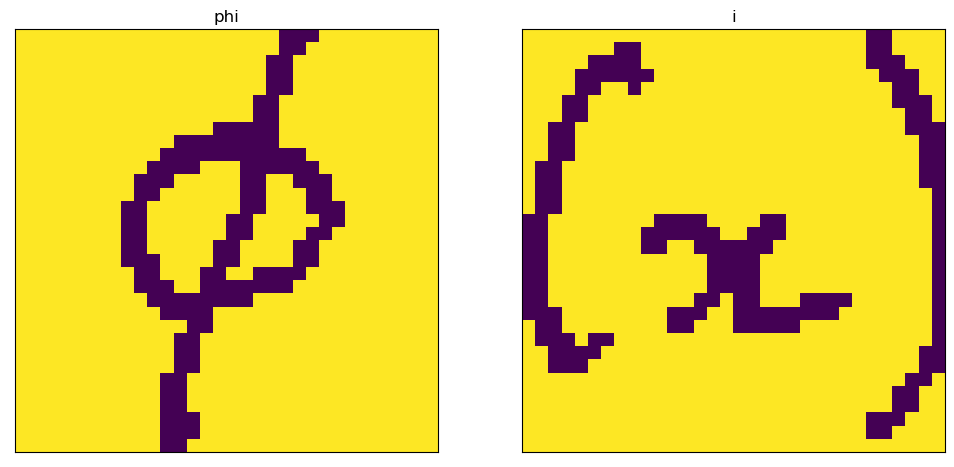

In [25]:
xx = []
if higher_proba:
    xx = convertInkmlToImg.genImgFromLGHypotheses(inkml, segmenter.toLG(higher_proba[2]), 32)[:-1]
for i, hyp in enumerate(xx, 1):
    plt.subplot(1, len(higher_proba[2]), i)
    if computeProbSeg(hyp, best_junk_not_junk_cnn)[1] == 0:
        plt.title(CROHME_dataset.classes[torch.max(best_recognition_model['training']['model'](torch.Tensor(hyp).unsqueeze(0).unsqueeze(0).to(device)), 1)[1]])
    else:
        plt.title("nope")
    plt.imshow(hyp)
    plt.xticks([])
    plt.yticks([])
plt.show()

We didn't have time to try our method on multiple InkML files, so we are showing you one of the complex files we have.  
It's not complex because of the different relations (here we only have "Right"s) but because there are multiple symbols in it, 6 strokes exactly. We can hypothetize the accuracy of our model to find the exact formula as 
$$ (acc_{junk\ classifier} * acc_{symbol\ classifier})^N $$
with $N$ the number of symbols in the expression. If we allow an error, we would get an accuracy looking like 
$$ (acc_{junk\ classifier} * acc_{symbol\ classifier})^{N-1} $$
And in a more general case :
$$ (acc_{junk\ classifier} * acc_{symbol\ classifier})^{N - N_{errors\ allowed}} $$

Of course, we are ommiting here the error due to the layout analysis, but we can think of it as quite small.

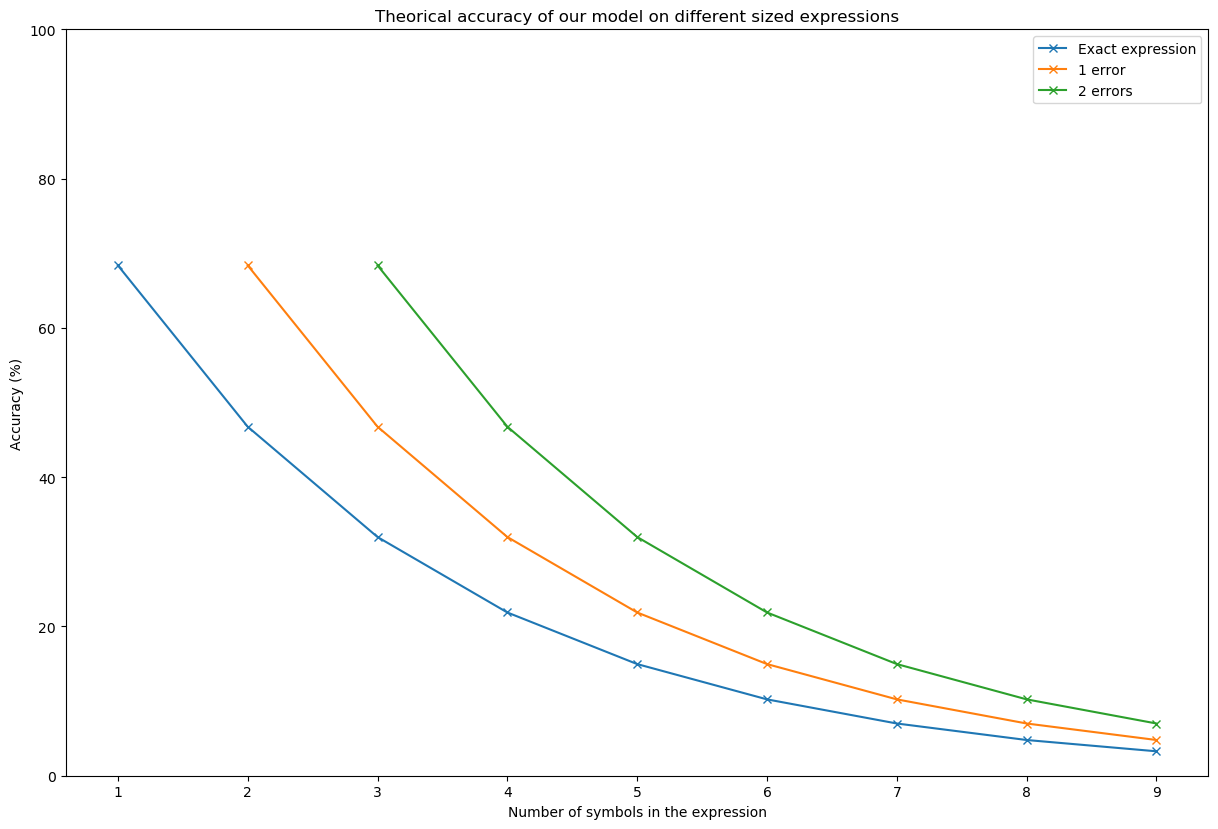

In [26]:
acc_junk = best_junk_model['test']['global']['acc']
acc_reco = best_recognition_model['test']['global']['acc']

accuracies = [[100 * (acc_junk * acc_reco)**n for n in range(1, 10)], range(1, 10)]
accuracies_1_error = [[100 * (acc_junk * acc_reco)**(n-1) for n in range(2, 10)], range(2, 10)]
accuracies_2_errors = [[100 * (acc_junk * acc_reco)**(n-2) for n in range(3, 10)], range(3, 10)]

plt.plot(accuracies[1], accuracies[0], "-x", label="Exact expression")
plt.plot(accuracies_1_error[1], accuracies_1_error[0], "-x", label="1 error")
plt.plot(accuracies_2_errors[1], accuracies_2_errors[0], "-x", label="2 errors")
plt.legend()
plt.tight_layout()

plt.title("Theorical accuracy of our model on different sized expressions")
plt.xlabel("Number of symbols in the expression")
plt.ylabel("Accuracy (%)")
plt.ylim((0, 100))
plt.show()

The real accuracy of our model is unknown for now as we should have relied on programs written especially for the CROHME, but are unavailable for now.  
These programs should have been able to look at a big amount of InkML files provided by the CROHME organizers, extract the ground truth and translate them into LG files. Then they would be able to compare the ground truth with our results to evaluate our model.

This would not require much work to recreate these functions, but for time reasons, we did not do that...

## Conclusion
Well, our model would have gotten much lower results than the one Vision Objects proposed in the CROHMEs, but still, we think that it can be quite powerful.  

Despite not being an innovative model, we learned a lot during this exercise. 
- We saw that CNN can do a very good job working on 2D images (while a RNN could have done an even better job thanks to the temporal dimension of the InkML format). 
- We've seen how to augment data when it comes to images.
- We saw (for the first time for us) how to make two different networks work together.
- We needed to study hundreds of network trainings, working with learning rate, optimizers, loss functions,... before displaying for you these results. (For more CNN structures, [you can find our second notebook here](annexe_1.html))
- Reading pages and pages of machine learning books and articles.

And here we are, proudly presenting you our work. 

Hope you enjoyed, bye!